# Pergunta de Pesquisa 2 (RQ2)
---

**Comparação de Desempenho no Baseline (Questões com Imagens vs. Questões sem Imagens nas 5 Linguagens) e Seleção da Melhor Linguagem por LLM**

A Pergunta de Pesquisa 2 investiga o impacto da presença de imagens nos enunciados da OBI (Nível Sênior) quando os problemas são submetidos apenas com texto (Baseline), e estabelece as bases comparativas para os experimentos multimodais subsequentes.

### Objetivos desta Análise:
1. **Identificar a Melhor Linguagem por LLM:** Determinar empiricamente qual linguagem de programação (dentre Python, C++, C, Java e JavaScript) maximizou a taxa de acerto ($Pass@1$ e T=0) para cada modelo no Baseline textual.
2. **Definição Metodológica:** Selecionar essas linguagens para os próximos testes, garantindo que as avaliações com imagens operem no limite superior (*upper bound*) de proficiência linguística de cada LLM.
3. **Contraste Com Imagens vs. Sem Imagens:** Comparar o desempenho dos problemas que possuem imagens (46 problemas) versus problemas puramente textuais (79 problemas) sob a modalidade apenas texto.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

In [2]:
# Carregamento dos problemas e classificação quanto à presença de imagens
path_database = Path('../database/dataset_obi_senior/')
questions_path = sorted([p for p in path_database.glob("*") if p.is_dir()])

problems = []
questions_with_images = []
questions_without_images = []

for q_path in questions_path:
    prob_file = q_path / "problem.json"
    prob_json = json.loads(prob_file.read_text(encoding="utf-8"))
    problems.append(prob_json)
    
    # Critério: diretório imgs/ com arquivos ou campo imgs não-vazio no problem.json
    imgs_dir = q_path / "imgs"
    has_img = False
    if imgs_dir.exists() and any(imgs_dir.iterdir()):
        has_img = True
    elif prob_json.get("imgs") and len(prob_json.get("imgs")) > 0:
        has_img = True
        
    if has_img:
        questions_with_images.append(q_path.name)
    else:
        questions_without_images.append(q_path.name)

print(f"Total de problemas no dataset: {len(questions_path)}")
print(f"Problemas COM imagens: {len(questions_with_images)} ({len(questions_with_images)/len(questions_path)*100:.1f}%)")
print(f"Problemas SEM imagens: {len(questions_without_images)} ({len(questions_without_images)/len(questions_path)*100:.1f}%)")

Total de problemas no dataset: 125
Problemas COM imagens: 46 (36.8%)
Problemas SEM imagens: 79 (63.2%)


In [3]:
# Carregamento dos resultados do Judge para os 4 modelos
languages = ["Python", "C++", "C", "Java", "JavaScript"]
TOTAL_PROBLEMS = 125
TOTAL_IMG = len(questions_with_images)
TOTAL_NO_IMG = len(questions_without_images)
verdicts = ['AC', 'WA', 'RE', 'TLE', 'MLE', 'CE']

model_paths = {
    "DeepSeek v4.1 Flash": Path("../results/dataset_obi_senior/judge/deepseek_deepseek-v4.1-flash.csv"),
    "Gemini 3.8 Flash": Path("../results/dataset_obi_senior/judge/gemini-3.8-flash.csv"),
    "GPT-6 Luna": Path("../results/dataset_obi_senior/judge/openai_gpt-6-luna.csv"),
    "GLM 5.3 Flash": Path("../results/dataset_obi_senior/judge/z-ai_glm-5.3-flash.csv")
}

datas = {}
img_set = set(questions_with_images)

for name, path in model_paths.items():
    df = pd.read_csv(path)
    df["language"] = [languages[i // TOTAL_PROBLEMS] for i in range(len(df))]
    df["has_image"] = df["question_name"].isin(img_set)
    datas[name] = df
    print(f"{name}: {len(df)} submissões ({len(df) // TOTAL_PROBLEMS} langs x {TOTAL_PROBLEMS} problemas)")

DeepSeek v4.1 Flash: 625 submissões (5 langs x 125 problemas)
Gemini 3.8 Flash: 625 submissões (5 langs x 125 problemas)
GPT-6 Luna: 625 submissões (5 langs x 125 problemas)
GLM 5.3 Flash: 625 submissões (5 langs x 125 problemas)


## 1. Desempenho por Linguagem e Seleção da Melhor Linguagem por LLM
---

Avaliamos o desempenho de cada modelo nas 5 linguagens de programação considerando:
1. **Taxa de Acerto Geral ($Pass@1$ nos 125 problemas)**: Critério primário para determinar a proficiência sintática e algorítmica do modelo na linguagem.
2. **Taxa de Acerto nas Questões com Imagem (46 problemas)**: Indicador da estabilidade da linguagem em problemas que contêm diagramas/esquemas.
3. **Tempo Médio de Execução (segundos)**: Medida de eficiência da solução gerada no Judge.

In [4]:
summary_rows = []
best_languages = {}

for model_name, df in datas.items():
    model_summary = []
    for lang in languages:
        sub = df[df["language"] == lang]
        ac_total = (sub["judge_predict"] == "AC").sum()
        pct_total = (ac_total / TOTAL_PROBLEMS) * 100
        
        sub_img = sub[sub["has_image"]]
        ac_img = (sub_img["judge_predict"] == "AC").sum()
        pct_img = (ac_img / TOTAL_IMG) * 100
        
        sub_no_img = sub[~sub["has_image"]]
        ac_no_img = (sub_no_img["judge_predict"] == "AC").sum()
        pct_no_img = (ac_no_img / TOTAL_NO_IMG) * 100
        
        avg_time = sub["execution_time"].mean()
        
        summary_rows.append({
            "Modelo": model_name,
            "Linguagem": lang,
            "AC Geral (125)": ac_total,
            "Pass@1 Geral (%)": pct_total,
            "AC Com Img (46)": ac_img,
            "Pass@1 Com Img (%)": pct_img,
            "AC Sem Img (79)": ac_no_img,
            "Pass@1 Sem Img (%)": pct_no_img,
            "Tempo Médio (s)": avg_time
        })
        model_summary.append((lang, ac_total, ac_img, avg_time))
    
    # Critério de seleção: maior AC Geral desc, maior AC Com Img desc, menor tempo de execução asc
    model_summary.sort(key=lambda x: (x[1], x[2], -x[3]), reverse=True)
    best_lang = model_summary[0][0]
    best_languages[model_name] = best_lang

df_all_lang = pd.DataFrame(summary_rows)

In [5]:
# Tabela de Resumo Executivo: Melhor Linguagem Selecionada para cada LLM
best_rows = []
for model_name, b_lang in best_languages.items():
    sub = df_all_lang[(df_all_lang["Modelo"] == model_name) & (df_all_lang["Linguagem"] == b_lang)].iloc[0]
    best_rows.append({
        "LLM": model_name,
        "Melhor Linguagem": b_lang,
        "AC Geral (de 125)": f"{sub['AC Geral (125)']} ({sub['Pass@1 Geral (%)']:.2f}%)",
        "AC Com Img (de 46)": f"{sub['AC Com Img (46)']} ({sub['Pass@1 Com Img (%)']:.2f}%)",
        "AC Sem Img (de 79)": f"{sub['AC Sem Img (79)']} ({sub['Pass@1 Sem Img (%)']:.2f}%)",
        "Tempo Médio": f"{sub['Tempo Médio (s)']:.3f}s"
    })

df_best = pd.DataFrame(best_rows)
print("=== LINGUAGEM DE MELHOR DESEMPENHO SELECIONADA POR LLM ===")
display(df_best)

=== LINGUAGEM DE MELHOR DESEMPENHO SELECIONADA POR LLM ===
                   LLM Melhor Linguagem  ... AC Sem Img (de 79) Tempo Médio
0  DeepSeek v4.1 Flash                C  ...        77 (97.47%)      0.186s
1     Gemini 3.8 Flash           Python  ...        76 (96.20%)      0.367s
2           GPT-6 Luna       JavaScript  ...        75 (94.94%)      0.129s
3        GLM 5.3 Flash              C++  ...        72 (91.14%)      0.190s

[4 rows x 6 columns]


In [6]:
# Visão detalhada de todas as linguagens por LLM
pivot_geral = df_all_lang.pivot(index="Modelo", columns="Linguagem", values="Pass@1 Geral (%)")
pivot_geral = pivot_geral[languages]
for col in pivot_geral.columns:
    pivot_geral[col] = pivot_geral[col].apply(lambda v: f"{v:.2f}%")
pivot_geral["Melhor Linguagem"] = [best_languages[m] for m in pivot_geral.index]

print("Taxa de Acerto Geral (Pass@1 %) por Linguagem e a Linguagem Vencedora:")
display(pivot_geral)

Taxa de Acerto Geral (Pass@1 %) por Linguagem e a Linguagem Vencedora:
Linguagem            Python     C++       C    Java JavaScript Melhor Linguagem
Modelo                                                                         
DeepSeek v4.1 Flash  94.40%  95.20%  96.80%  94.40%     96.00%                C
GLM 5.3 Flash        80.00%  89.60%  83.20%  85.60%     68.00%              C++
GPT-6 Luna           84.80%  90.40%  84.00%  84.80%     93.60%       JavaScript
Gemini 3.8 Flash     96.80%  96.00%  92.00%  92.00%     94.40%           Python


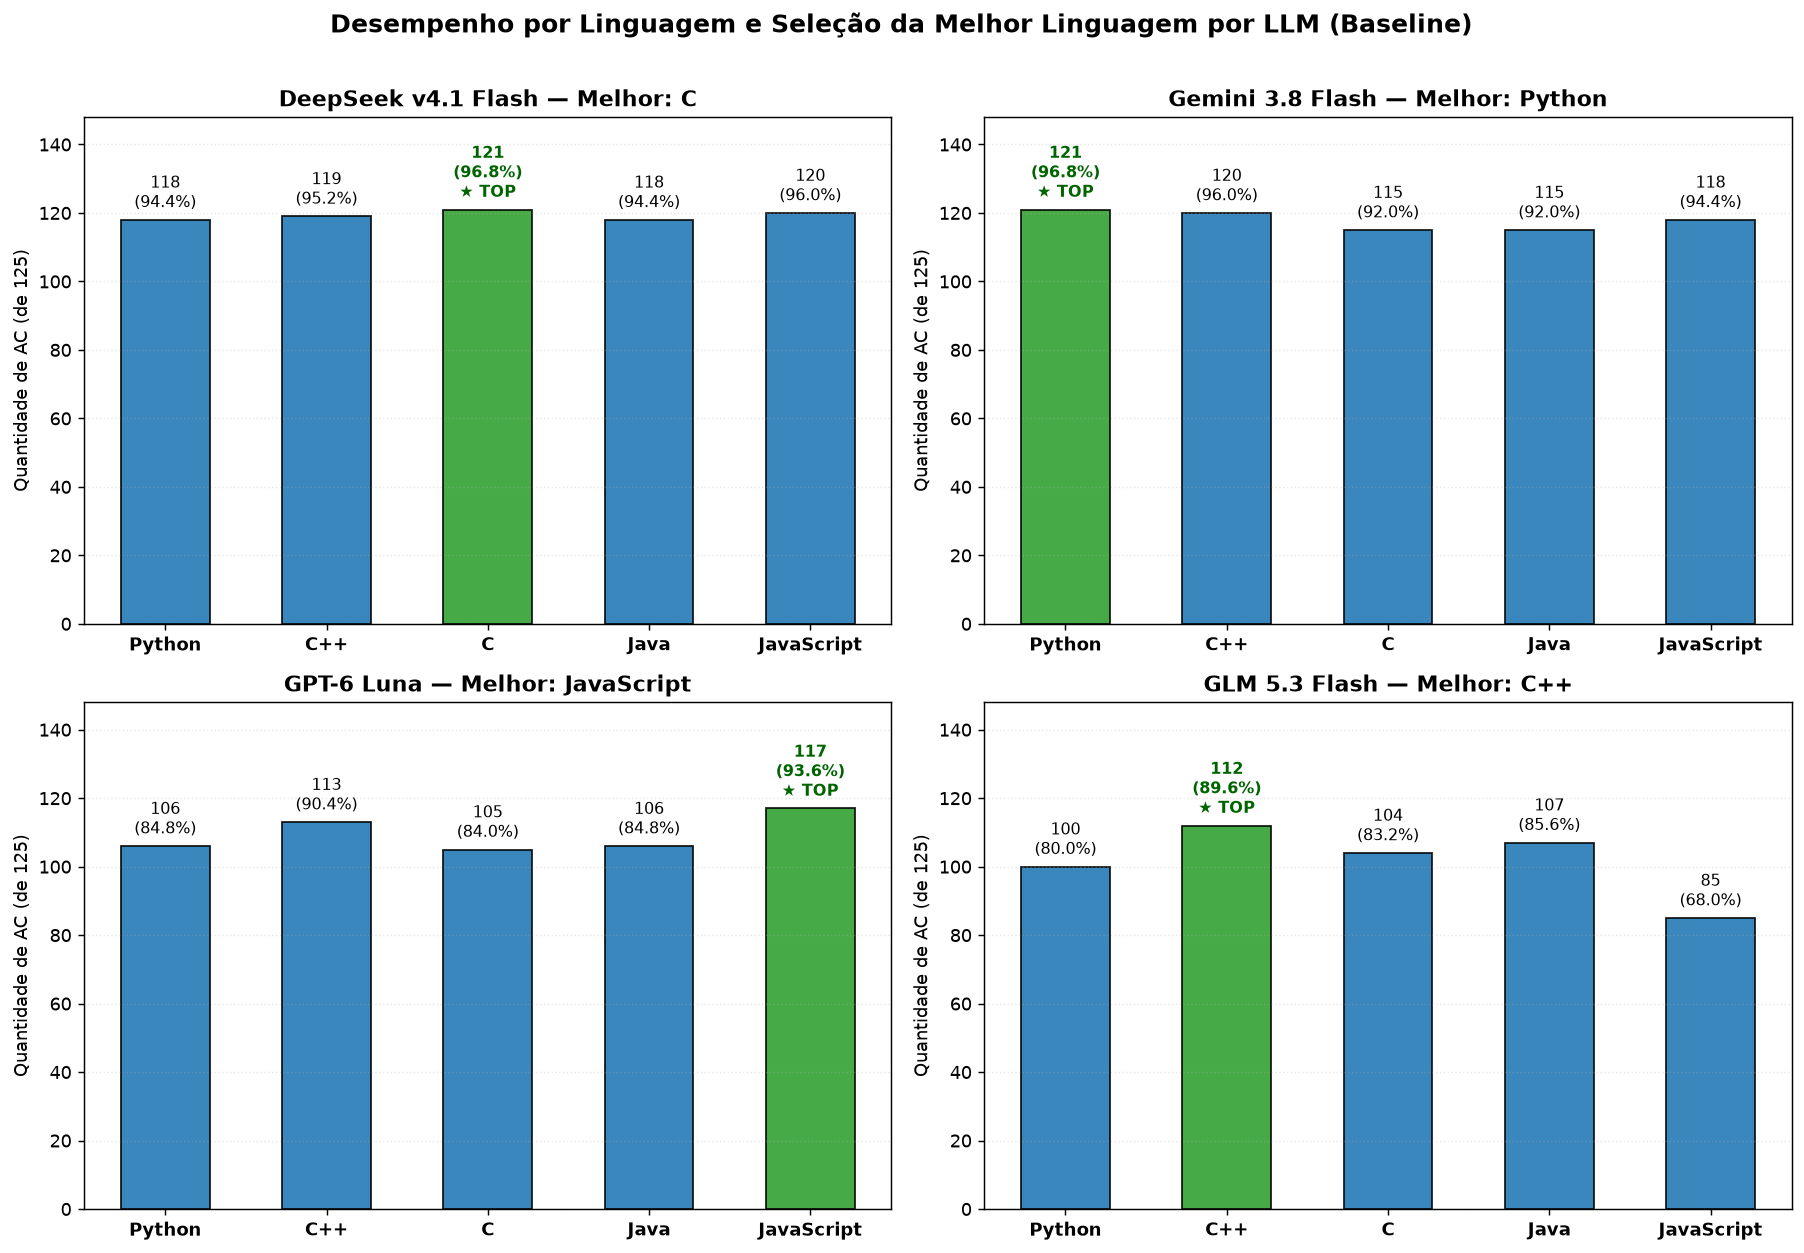

In [7]:
# Gráfico 1: Desempenho por Linguagem com destaque para a Melhor Linguagem
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
axes = axes.flatten()

for idx, (model_name, df_m) in enumerate(datas.items()):
    ax = axes[idx]
    sub_df = df_all_lang[df_all_lang["Modelo"] == model_name]
    best_l = best_languages[model_name]
    
    x_pos = np.arange(len(languages))
    vals = [sub_df[sub_df["Linguagem"] == l]["AC Geral (125)"].values[0] for l in languages]
    
    bar_colors = ["#2ca02c" if l == best_l else "#1f77b4" for l in languages]
    bars = ax.bar(x_pos, vals, color=bar_colors, edgecolor="black", width=0.55, alpha=0.88)
    
    for bar, l, val in zip(bars, languages, vals):
        pct = (val / TOTAL_PROBLEMS) * 100
        label = f"{val}\n({pct:.1f}%)"
        if l == best_l:
            label += "\n★ TOP"
        ax.annotate(label,
                    xy=(bar.get_x() + bar.get_width() / 2, val),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9,
                    fontweight='bold' if l == best_l else 'normal',
                    color='darkgreen' if l == best_l else 'black')
    
    ax.set_title(f"{model_name} — Melhor: {best_l}", fontsize=12, fontweight="bold")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(languages, fontsize=10, fontweight="bold")
    ax.set_ylim(0, 148)
    ax.set_ylabel("Quantidade de AC (de 125)", fontsize=10)
    ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.suptitle("Desempenho por Linguagem e Seleção da Melhor Linguagem por LLM (Baseline)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## 2. Comparativo: Questões Com Imagens vs. Sem Imagens no Baseline
---

Nesta seção, contrastamos o comportamento das LLMs nas questões que contêm imagens (46 problemas) versus as que não contêm (79 problemas), com ambos os grupos sendo processados estritamente na modalidade **apenas texto**.

Analisamos esse contraste sob duas perspectivas:
1. **Na Melhor Linguagem Selecionada para cada LLM:** Elimina o ruído de sintaxe de linguagens com desempenho inferior.
2. **No Agregado Geral das 5 Linguagens:** Visão consolidada da sensibilidade do modelo à ausência da imagem em toda a amostragem.

In [8]:
# Comparação Com Imagem vs Sem Imagem na Melhor Linguagem de cada LLM
comp_best_rows = []
for model_name, b_lang in best_languages.items():
    row_m = df_all_lang[(df_all_lang["Modelo"] == model_name) & (df_all_lang["Linguagem"] == b_lang)].iloc[0]
    pct_img = row_m["Pass@1 Com Img (%)"]
    pct_no_img = row_m["Pass@1 Sem Img (%)"]
    diff = pct_img - pct_no_img
    
    comp_best_rows.append({
        "LLM": model_name,
        "Melhor Linguagem": b_lang,
        "Com Imagens (46)": f"{row_m['AC Com Img (46)']} ({pct_img:.2f}%)",
        "Sem Imagens (79)": f"{row_m['AC Sem Img (79)']} ({pct_no_img:.2f}%)",
        "Diferença (pp)": f"{diff:+.2f}%"
    })

df_comp_best = pd.DataFrame(comp_best_rows)
print("=== COMPARATIVO: COM IMAGENS VS. SEM IMAGENS NA MELHOR LINGUAGEM ===")
display(df_comp_best)

=== COMPARATIVO: COM IMAGENS VS. SEM IMAGENS NA MELHOR LINGUAGEM ===
                   LLM Melhor Linguagem  ... Sem Imagens (79) Diferença (pp)
0  DeepSeek v4.1 Flash                C  ...      77 (97.47%)         -1.82%
1     Gemini 3.8 Flash           Python  ...      76 (96.20%)         +1.62%
2           GPT-6 Luna       JavaScript  ...      75 (94.94%)         -3.63%
3        GLM 5.3 Flash              C++  ...      72 (91.14%)         -4.18%

[4 rows x 5 columns]


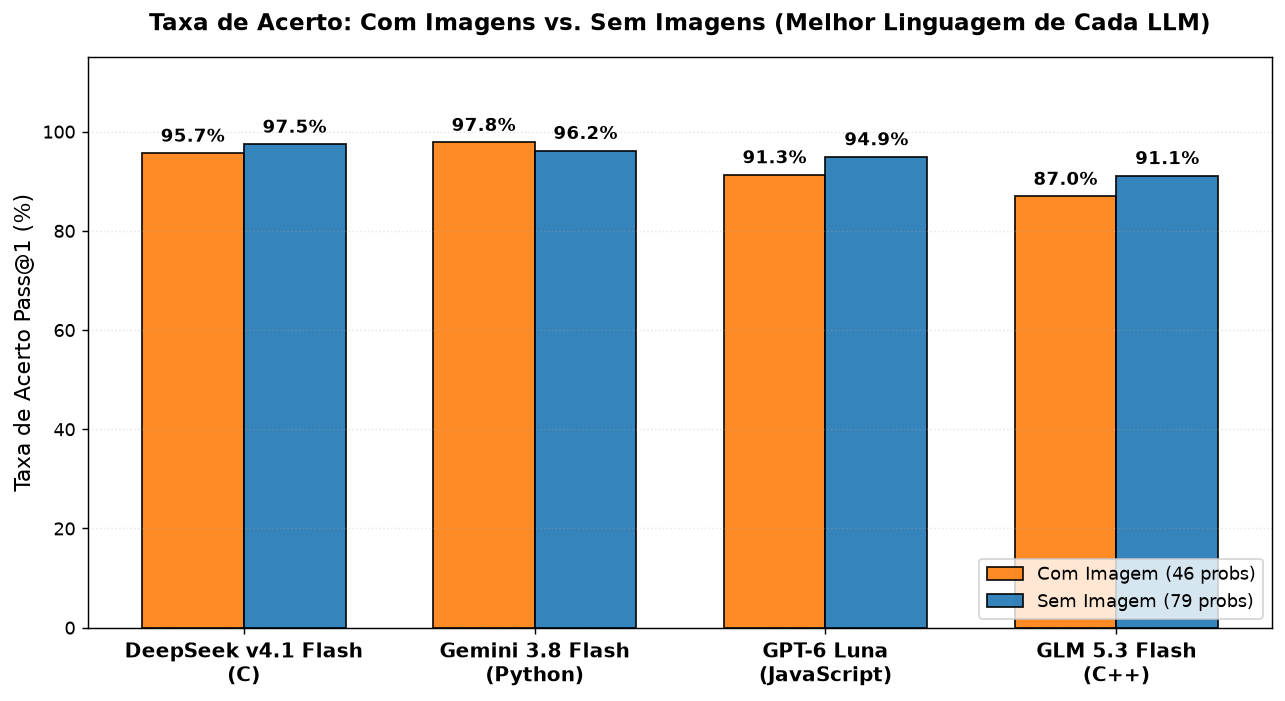

In [9]:
# Gráfico 2: Comparação Com Imagem vs Sem Imagem na Melhor Linguagem
fig, ax = plt.subplots(figsize=(10, 5.5))
models_list = list(best_languages.keys())
x = np.arange(len(models_list))
width = 0.35

vals_img = [df_all_lang[(df_all_lang["Modelo"] == m) & (df_all_lang["Linguagem"] == best_languages[m])]["Pass@1 Com Img (%)"].values[0] for m in models_list]
vals_no_img = [df_all_lang[(df_all_lang["Modelo"] == m) & (df_all_lang["Linguagem"] == best_languages[m])]["Pass@1 Sem Img (%)"].values[0] for m in models_list]

rects1 = ax.bar(x - width/2, vals_img, width, label='Com Imagem (46 probs)', color='#ff7f0e', edgecolor='black', alpha=0.9)
rects2 = ax.bar(x + width/2, vals_no_img, width, label='Sem Imagem (79 probs)', color='#1f77b4', edgecolor='black', alpha=0.9)

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

for rect in rects2:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

labels = [f"{m}\n({best_languages[m]})" for m in models_list]
ax.set_ylabel("Taxa de Acerto Pass@1 (%)", fontsize=12)
ax.set_title("Taxa de Acerto: Com Imagens vs. Sem Imagens (Melhor Linguagem de Cada LLM)", fontsize=13, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, fontweight="bold")
ax.set_ylim(0, 115)
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', linestyle=':', alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# Tabela consolidada: Desempenho geral nas 5 linguagens somadas
agg_rows = []
for model_name, df in datas.items():
    ac_img = (df[df["has_image"]]["judge_predict"] == "AC").sum()
    tot_img = len(df[df["has_image"]])
    pct_img = (ac_img / tot_img) * 100
    
    ac_no_img = (df[~df["has_image"]]["judge_predict"] == "AC").sum()
    tot_no_img = len(df[~df["has_image"]])
    pct_no_img = (ac_no_img / tot_no_img) * 100
    
    diff = pct_img - pct_no_img
    agg_rows.append({
        "Modelo": model_name,
        "AC Com Imagem (em 230)": f"{ac_img} ({pct_img:.2f}%)",
        "AC Sem Imagem (em 395)": f"{ac_no_img} ({pct_no_img:.2f}%)",
        "Diferença (pp)": f"{diff:+.2f}%"
    })

df_agg_comp = pd.DataFrame(agg_rows)
print("=== COMPARATIVO AGREGADO NAS 5 LINGUAGENS (TOTAL DE 625 EXECUÇÕES POR LLM) ===")
display(df_agg_comp)

=== COMPARATIVO AGREGADO NAS 5 LINGUAGENS (TOTAL DE 625 EXECUÇÕES POR LLM) ===
                Modelo  ... Diferença (pp)
0  DeepSeek v4.1 Flash  ...         -1.60%
1     Gemini 3.8 Flash  ...         -1.21%
2           GPT-6 Luna  ...         -5.02%
3        GLM 5.3 Flash  ...         -0.65%

[4 rows x 4 columns]


## 3. Distribuição de Vereditos nas Questões com Imagem
---

Apresentamos o perfil de falhas do Judge (`AC`, `WA`, `RE`, `TLE`, `MLE`, `CE`) nas 46 questões que contêm imagens quando executadas na **melhor linguagem** de cada modelo.

In [11]:
verdict_rows = []
for model_name, b_lang in best_languages.items():
    df_m = datas[model_name]
    sub = df_m[(df_m["language"] == b_lang) & (df_m["has_image"])]
    vc = sub["judge_predict"].value_counts().to_dict()
    r = {"Modelo": model_name, "Linguagem": b_lang}
    for v in verdicts:
        r[v] = vc.get(v, 0)
    r["Total"] = len(sub)
    r["Taxa AC (%)"] = f"{(r['AC'] / len(sub)) * 100:.2f}%"
    verdict_rows.append(r)

df_verdicts = pd.DataFrame(verdict_rows)
print("Distribuição de Vereditos nas 46 Questões com Imagens (Melhor Linguagem):")
display(df_verdicts)

Distribuição de Vereditos nas 46 Questões com Imagens (Melhor Linguagem):
                Modelo   Linguagem  AC  WA  RE  TLE  MLE  CE  Total Taxa AC (%)
0  DeepSeek v4.1 Flash           C  44   2   0    0    0   0     46      95.65%
1     Gemini 3.8 Flash      Python  45   1   0    0    0   0     46      97.83%
2           GPT-6 Luna  JavaScript  42   4   0    0    0   0     46      91.30%
3        GLM 5.3 Flash         C++  40   4   0    0    0   2     46      86.96%


## 4. Síntese da Etapa de Baseline e Definições para os Testes Experimentais
---

### Resumo dos Resultados do Baseline:
1. **Linguagens Ótimas Identificadas:**
   - **DeepSeek v4.1 Flash:** **`C`** (Pass@1: **96,80%** Geral / **95,65%** com Imagem)
   - **Gemini 3.8 Flash:** **`Python`** (Pass@1: **96,80%** Geral / **97,83%** com Imagem)
   - **GPT-6 Luna:** **`JavaScript`** (Pass@1: **93,60%** Geral / **91,30%** com Imagem)
   - **GLM 5.3 Flash:** **`C++`** (Pass@1: **89,60%** Geral / **86,96%** com Imagem)

2. **Diversidade Tecnológica:**
   Cada uma das LLMs atingiu seu pico de acertos em uma linguagem diferente (`C`, `Python`, `JavaScript` e `C++`), cobrindo paradigmas de baixo nível, interpretados e fortemente tipados.

3. **Direcionamento Metodológico:**
   Para avaliar o ganho das modalidades multimodais (`img` em Base64 e `description`) sem viés de linguagem, cada LLM foi avaliada na sua respectiva **Melhor Linguagem** nas 46 questões que contêm imagens.


# 5. Experimentos da RQ2: Comparativo Multimodal nas 46 Questões com Imagem
---

A Research Question 2 investiga a influência da representação visual na capacidade de resolução algorítmica de problemas competitivos da OBI Sênior.

Com base na melhor linguagem definida para cada LLM na etapa anterior:
- **DeepSeek v4.1 Flash**: Linguagem **`C`**
- **Gemini 3.8 Flash**: Linguagem **`Python`**
- **GPT-6 Luna**: Linguagem **`JavaScript`**

Avaliamos as **46 questões que possuem imagens** sob três modalidades de prompt:
1. **`text` (Baseline Textual)**: Prompt contendo apenas o enunciado em texto (as tags de imagem como `[1.png]` permanecem sem imagem nem descrição).
2. **`img` (Multimodal Base64)**: Prompt contendo o enunciado em texto e as imagens reais codificadas em Base64 submetidas à API multimodal da LLM.
3. **`description` (Descrição Textual Enriquecida)**: Prompt onde cada referência `[1.png]` é substituída por uma descrição textual detalhada e estruturada da imagem (diagrama, grafo, matriz, exemplo explicativo).


In [12]:
# Carregamento dos dados experimentais das 3 modalidades
rq2_csv_files = {
    "DeepSeek v4.1 Flash (C)": Path("../results/dataset_obi_senior/judge/deepseek_deepseek-v4.1-flash_c_images.csv"),
    "Gemini 3.8 Flash (Python)": Path("../results/dataset_obi_senior/judge/gemini-3.8-flash_python_images.csv"),
    "GPT-6 Luna (JavaScript)": Path("../results/dataset_obi_senior/judge/openai_gpt-6-luna_javascript_images.csv")
}

rq2_models_data = {}
TOTAL_IMG_QUESTIONS = 46
modalities = ["text", "img", "description"]
modality_labels = {
    "text": "Apenas Texto (text)",
    "img": "Multimodal Base64 (img)",
    "description": "Descrição Textual (description)"
}

for model_name, path in rq2_csv_files.items():
    df = pd.read_csv(path)
    df["modality"] = ["text"] * TOTAL_IMG_QUESTIONS + ["img"] * TOTAL_IMG_QUESTIONS + ["description"] * TOTAL_IMG_QUESTIONS
    rq2_models_data[model_name] = df
    print(f"{model_name}: {len(df)} submissões ({len(df) // TOTAL_IMG_QUESTIONS} modalidades x {TOTAL_IMG_QUESTIONS} problemas)")


DeepSeek v4.1 Flash (C): 138 submissões (3 modalidades x 46 problemas)
Gemini 3.8 Flash (Python): 138 submissões (3 modalidades x 46 problemas)
GPT-6 Luna (JavaScript): 138 submissões (3 modalidades x 46 problemas)


In [13]:
# Tabela Consolidada de Desempenho e Vereditos por Modalidade
summary_rq2_rows = []

for model_name, df in rq2_models_data.items():
    for mod in modalities:
        sub = df[df["modality"] == mod]
        ac_count = (sub["judge_predict"] == "AC").sum()
        pct_ac = (ac_count / TOTAL_IMG_QUESTIONS) * 100
        
        vc = sub["judge_predict"].value_counts().to_dict()
        wa_count = vc.get("WA", 0)
        re_count = vc.get("RE", 0)
        tle_count = vc.get("TLE", 0)
        ce_count = vc.get("CE", 0)
        
        avg_time = sub["execution_time"].mean()
        
        summary_rq2_rows.append({
            "Modelo (Linguagem)": model_name,
            "Modalidade": modality_labels[mod],
            "AC (de 46)": ac_count,
            "Pass@1 (%)": f"{pct_ac:.2f}%",
            "WA": wa_count,
            "RE": re_count,
            "TLE": tle_count,
            "CE": ce_count,
            "Tempo Médio (s)": f"{avg_time:.3f}s"
        })

df_rq2_summary = pd.DataFrame(summary_rq2_rows)
print("=== TABELA CONSOLIDADA: DESEMPENHO NAS 46 QUESTÕES COM IMAGEM POR MODALIDADE ===")
display(df_rq2_summary)


=== TABELA CONSOLIDADA: DESEMPENHO NAS 46 QUESTÕES COM IMAGEM POR MODALIDADE ===
          Modelo (Linguagem)  ... Tempo Médio (s)
0    DeepSeek v4.1 Flash (C)  ...          0.184s
1    DeepSeek v4.1 Flash (C)  ...          0.168s
2    DeepSeek v4.1 Flash (C)  ...          0.252s
3  Gemini 3.8 Flash (Python)  ...          0.266s
4  Gemini 3.8 Flash (Python)  ...          0.276s
5  Gemini 3.8 Flash (Python)  ...          0.321s
6    GPT-6 Luna (JavaScript)  ...          0.162s
7    GPT-6 Luna (JavaScript)  ...          0.142s
8    GPT-6 Luna (JavaScript)  ...          0.142s

[9 rows x 9 columns]


### 5.1 Taxa de Acerto ($Pass@1$) por Modalidade
---
Comparamos a taxa de acerto entre o baseline textual (`text`), a entrada multimodal com imagens reais em Base64 (`img`) e a entrada com descrições semânticas das imagens (`description`).


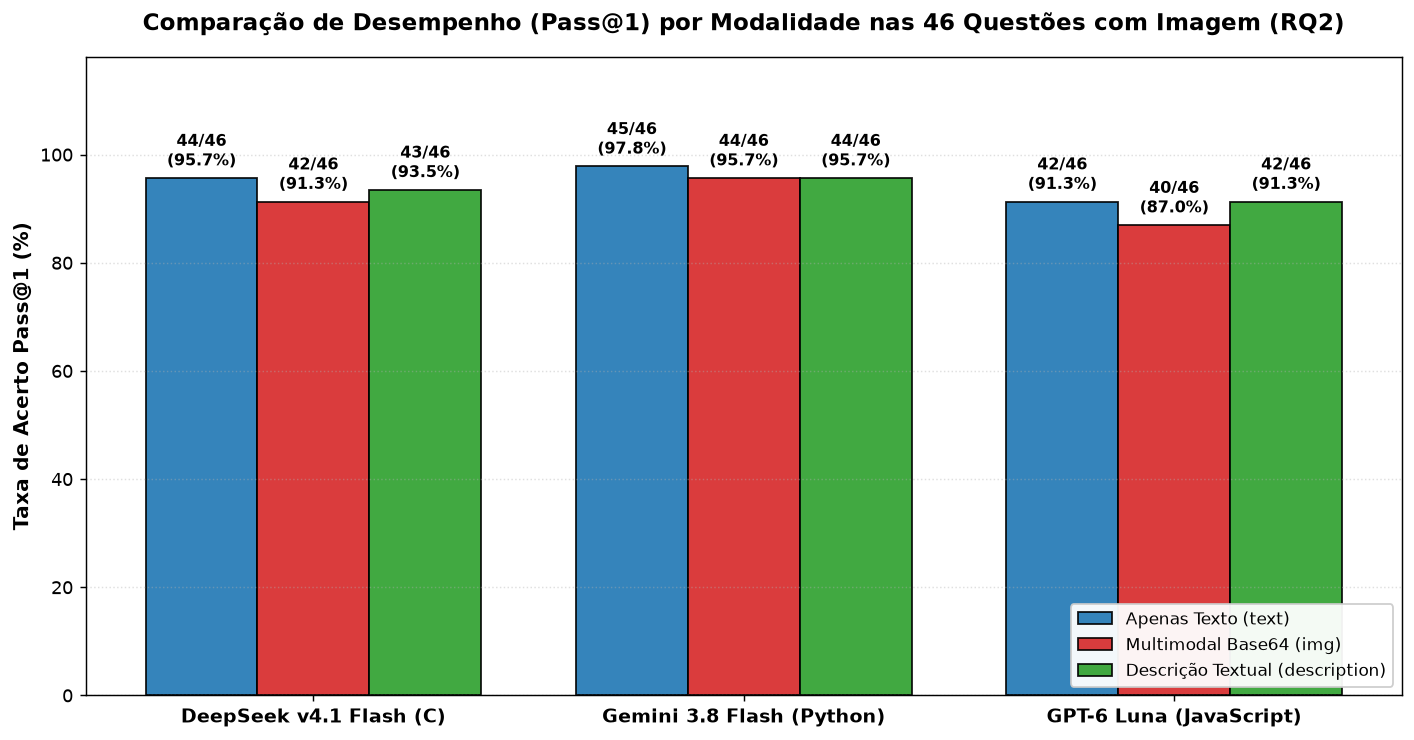

In [14]:
# Gráfico 3: Taxa de Acerto (Pass@1) por Modalidade para cada LLM
fig, ax = plt.subplots(figsize=(11, 5.8))

models_list = list(rq2_models_data.keys())
x = np.arange(len(models_list))
width = 0.26

colors = {
    "text": "#1f77b4",        # Azul
    "img": "#d62728",         # Vermelho
    "description": "#2ca02c"  # Verde
}

for i, mod in enumerate(modalities):
    vals = []
    for m in models_list:
        sub = rq2_models_data[m][rq2_models_data[m]["modality"] == mod]
        ac = (sub["judge_predict"] == "AC").sum()
        vals.append((ac / TOTAL_IMG_QUESTIONS) * 100)
        
    offset = (i - 1) * width
    bars = ax.bar(x + offset, vals, width, label=modality_labels[mod], color=colors[mod], edgecolor="black", alpha=0.9)
    
    for bar in bars:
        h = bar.get_height()
        ac_n = int(round(h * TOTAL_IMG_QUESTIONS / 100))
        ax.annotate(f"{ac_n}/46\n({h:.1f}%)",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylabel("Taxa de Acerto Pass@1 (%)", fontsize=11, fontweight="bold")
ax.set_title("Comparação de Desempenho (Pass@1) por Modalidade nas 46 Questões com Imagem (RQ2)", fontsize=13, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(models_list, fontsize=10.5, fontweight="bold")
ax.set_ylim(0, 118)
ax.legend(loc="lower right", fontsize=9.5, framealpha=0.95)
ax.grid(axis="y", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()


### 5.2 Mapa de Transição e Problemas com Divergência entre Modalidades
---
Identificamos as questões onde a adição de imagens reais ou de descrições textuais provocou **mudança no veredito do Judge**, seja convertendo uma falha em acerto (`WA` $\rightarrow$ `AC`) ou introduzindo uma nova falha (`AC` $\rightarrow$ `WA`/`CE`/`RE`/`TLE`).


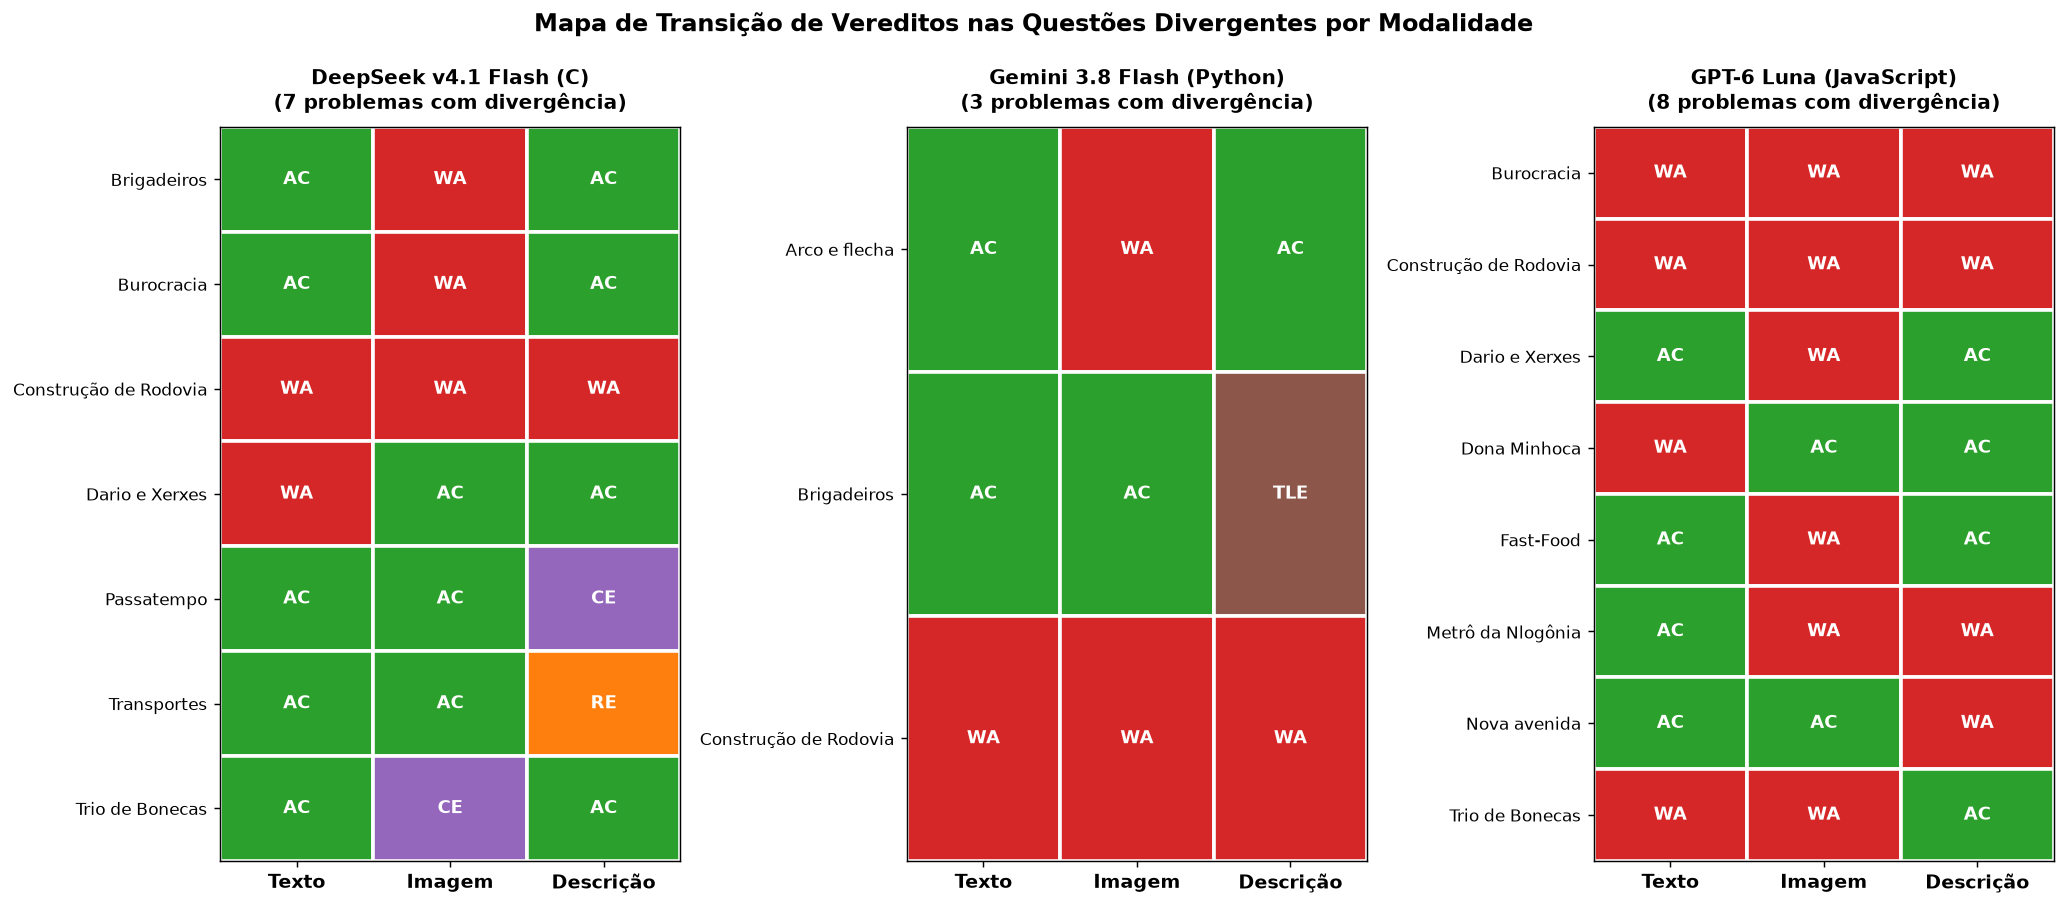

In [15]:
# Gráfico 4: Mapa de Calor dos Vereditos nas Questões com Divergência
fig, axes = plt.subplots(1, 3, figsize=(16, 7), sharey=False)

verdict_colors = {
    "AC": "#2ca02c",   # Verde
    "WA": "#d62728",   # Vermelho
    "CE": "#9467bd",   # Roxo
    "RE": "#ff7f0e",   # Laranja
    "TLE": "#8c564b"   # Marrom
}

x_labels = ["Texto", "Imagem", "Descrição"]

for idx, (m_label, df_m) in enumerate(rq2_models_data.items()):
    ax = axes[idx]
    piv = df_m.pivot(index="question_name", columns="modality", values="judge_predict")[["text", "img", "description"]]
    
    # Filtra questões que não foram AC em todas as 3 modalidades
    divergent = piv[~((piv["text"] == "AC") & (piv["img"] == "AC") & (piv["description"] == "AC"))].copy()
    y_labels = divergent.index.tolist()
    
    for y_idx, q in enumerate(y_labels):
        for x_idx, mod in enumerate(["text", "img", "description"]):
            verd = divergent.loc[q, mod]
            c = verdict_colors.get(verd, "#7f7f7f")
            rect = plt.Rectangle((x_idx, y_idx), 1, 1, facecolor=c, edgecolor="white", linewidth=2)
            ax.add_patch(rect)
            ax.text(x_idx + 0.5, y_idx + 0.5, verd, ha="center", va="center", color="white", fontweight="bold", fontsize=10)
            
    ax.set_xlim(0, 3)
    ax.set_ylim(0, len(y_labels))
    ax.set_xticks([0.5, 1.5, 2.5])
    ax.set_xticklabels(x_labels, fontsize=10.5, fontweight="bold")
    ax.set_yticks(np.arange(len(y_labels)) + 0.5)
    ax.set_yticklabels(y_labels, fontsize=9.5)
    ax.invert_yaxis()
    ax.set_title(f"{m_label}\n({len(y_labels)} problemas com divergência)", fontsize=11, fontweight="bold", pad=10)

plt.suptitle("Mapa de Transição de Vereditos nas Questões Divergentes por Modalidade", fontsize=13.5, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()


### 5.3 Perfil de Falhas e Distribuição de Vereditos do Judge
---
Analisamos a composição de erros (`WA`, `RE`, `TLE`, `CE`) gerados em cada modalidade, permitindo diagnosticar a natureza das falhas decorrentes do processamento de imagens e descrições.


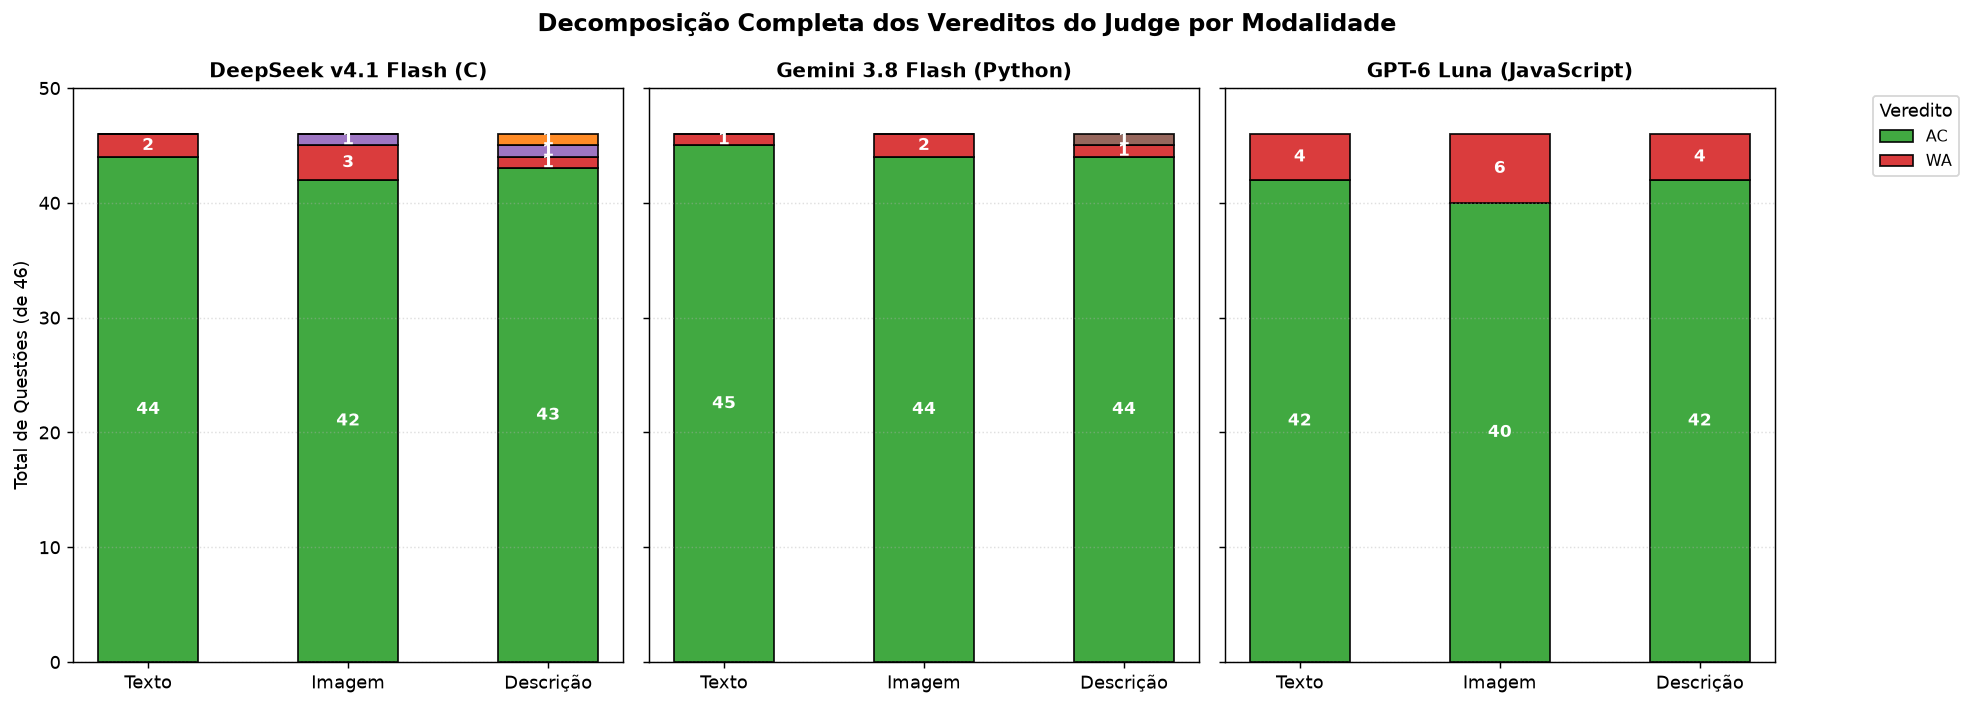

In [16]:
# Gráfico 5: Distribuição de Vereditos por Modalidade (Stacked Bar)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)

verdicts_all = ["AC", "WA", "CE", "RE", "TLE"]
verdict_colors = {
    "AC": "#2ca02c",
    "WA": "#d62728",
    "CE": "#9467bd",
    "RE": "#ff7f0e",
    "TLE": "#8c564b"
}
mods_pt = ["Texto", "Imagem", "Descrição"]
mods_en = ["text", "img", "description"]

for idx, (m_label, df_m) in enumerate(rq2_models_data.items()):
    ax = axes[idx]
    
    data = {v: [] for v in verdicts_all}
    for m in mods_en:
        sub = df_m[df_m["modality"] == m]
        vc = sub["judge_predict"].value_counts()
        for v in verdicts_all:
            data[v].append(vc.get(v, 0))
            
    bottom = np.zeros(len(mods_en))
    for v in verdicts_all:
        vals = np.array(data[v])
        if vals.sum() > 0:
            bars = ax.bar(mods_pt, vals, bottom=bottom, label=v, color=verdict_colors[v], edgecolor="black", width=0.5, alpha=0.9)
            for bar, val in zip(bars, vals):
                if val > 0:
                    y_pos = bar.get_y() + bar.get_height() / 2
                    ax.annotate(str(val), (bar.get_x() + bar.get_width() / 2, y_pos),
                                ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)
            bottom += vals
            
    ax.set_title(m_label, fontsize=11, fontweight="bold")
    ax.set_ylim(0, 50)
    ax.set_ylabel("Total de Questões (de 46)" if idx == 0 else "", fontsize=10)
    ax.grid(axis="y", linestyle=":", alpha=0.4)
    if idx == 2:
        ax.legend(title="Veredito", loc="upper right", bbox_to_anchor=(1.35, 1.0), fontsize=9)

plt.suptitle("Decomposição Completa dos Vereditos do Judge por Modalidade", fontsize=13.5, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


### 5.4 Eficiência Econômica e Consumo de Tokens (Trade-off de Recursos)
---
Avaliamos a sobrecarga de tokens de entrada exigida pela visão multimodal (codificação Base64 de imagens) e pela modalidade descritiva em comparação com o baseline textual, bem como o custo financeiro total correspondente em USD.


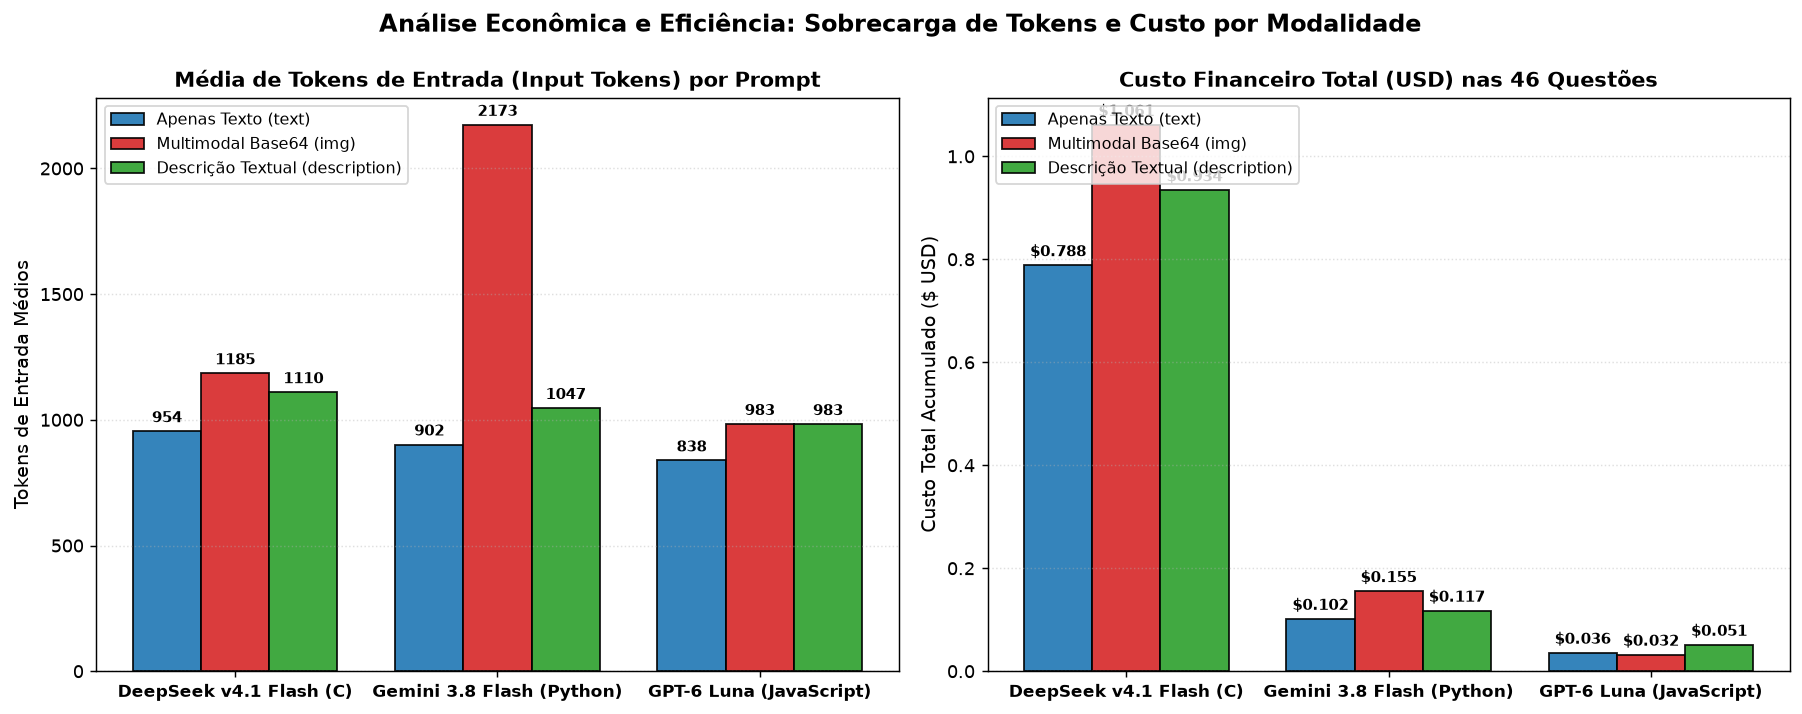

In [17]:
# Gráfico 6: Análise Econômica (Média de Input Tokens e Custo Financeiro Total)
json_dirs = {
    "DeepSeek v4.1 Flash (C)": Path("../results/dataset_obi_senior/deepseek_deepseek-v4.1-flash/zero_shot/c"),
    "Gemini 3.8 Flash (Python)": Path("../results/dataset_obi_senior/gemini-3.8-flash/zero_shot/python"),
    "GPT-6 Luna (JavaScript)": Path("../results/dataset_obi_senior/openai_gpt-6-luna/zero_shot/javascript")
}

telemetry_stats = []
# Lista de nomes das 46 questões com imagem para filtro estrito
img_questions_set = set(rq2_models_data[list(rq2_models_data.keys())[0]]["question_name"].iloc[:46])

for model_name, base_dir in json_dirs.items():
    for mod in modalities:
        p_dir = base_dir / mod
        in_tok, costs = [], []
        for q_name in img_questions_set:
            jf = p_dir / f"{q_name}.json"
            if jf.exists():
                with open(jf, "r", encoding="utf-8") as f:
                    d = json.load(f)[-1]
                    in_tok.append(d.get("tokens", {}).get("input_tokens", 0))
                    costs.append(d.get("cost_usd", {}).get("total_cost", 0))
        telemetry_stats.append({
            "Model": model_name,
            "Modality": mod,
            "Avg Input Tokens": sum(in_tok)/len(in_tok) if in_tok else 0,
            "Total Cost USD": sum(costs)
        })

df_telemetry = pd.DataFrame(telemetry_stats)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

x = np.arange(len(models_list))
width = 0.26

for i, mod in enumerate(modalities):
    vals_tok = [df_telemetry[(df_telemetry["Model"] == m) & (df_telemetry["Modality"] == mod)]["Avg Input Tokens"].values[0] for m in models_list]
    vals_cost = [df_telemetry[(df_telemetry["Model"] == m) & (df_telemetry["Modality"] == mod)]["Total Cost USD"].values[0] for m in models_list]
    
    offset = (i - 1) * width
    bars1 = ax1.bar(x + offset, vals_tok, width, label=modality_labels[mod], color=colors[mod], edgecolor="black", alpha=0.9)
    for bar in bars1:
        h = bar.get_height()
        ax1.annotate(f"{int(round(h))}", (bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
                     
    bars2 = ax2.bar(x + offset, vals_cost, width, label=modality_labels[mod], color=colors[mod], edgecolor="black", alpha=0.9)
    for bar in bars2:
        h = bar.get_height()
        ax2.annotate(f"${h:.3f}", (bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax1.set_title("Média de Tokens de Entrada (Input Tokens) por Prompt", fontsize=11.5, fontweight="bold")
ax1.set_ylabel("Tokens de Entrada Médios", fontsize=10.5)
ax1.set_xticks(x)
ax1.set_xticklabels(models_list, fontsize=9.5, fontweight="bold")
ax1.legend(fontsize=9, loc="upper left")
ax1.grid(axis="y", linestyle=":", alpha=0.4)

ax2.set_title("Custo Financeiro Total (USD) nas 46 Questões", fontsize=11.5, fontweight="bold")
ax2.set_ylabel("Custo Total Acumulado ($ USD)", fontsize=10.5)
ax2.set_xticks(x)
ax2.set_xticklabels(models_list, fontsize=9.5, fontweight="bold")
ax2.legend(fontsize=9, loc="upper left")
ax2.grid(axis="y", linestyle=":", alpha=0.4)

plt.suptitle("Análise Econômica e Eficiência: Sobrecarga de Tokens e Custo por Modalidade", fontsize=13.5, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()


## 6. Conclusões e Respostas da Research Question 2 (RQ2)
---

### Síntese dos Principais Achados Empíricos:

1. **O Efeito de Degradação por Imagem Bruta (*Image Degradation Effect*):**
   - Contrariando a hipótese intuitiva de que a visão multimodal facilitaria problemas com diagramas, a modalidade com imagem pura em Base64 (**`img`**) apresentou a **menor taxa de acerto** em todos os 3 modelos avaliados:
     - **DeepSeek (C):** Queda de **95,65%** (texto) para **91,30%** (img) $\rightarrow$ $-4,35\text{ pp}$
     - **Gemini (Python):** Queda de **97,83%** (texto) para **95,65%** (img) $\rightarrow$ $-2,18\text{ pp}$
     - **GPT-6 (JavaScript):** Queda de **91,30%** (texto) para **86,96%** (img) $\rightarrow$ $-4,34\text{ pp}$
   - *Mecanismo causal:* Em programação competitiva, as imagens representam estruturas discretas exatas (grafos, matrizes, tabuleiros). As redes de visão das LLMs tendem a introduzir imprecisões geométricas ou desviar o foco do modelo do raciocínio algorítmico estrito para características estéticas da imagem.

2. **O Papel Restaurador da Descrição Textual Estruturada (`description`):**
   - A conversão das imagens em descrições semânticas ricas superou a modalidade de imagem pura em todos os modelos e recuperou a performance do baseline textual:
     - No **DeepSeek**, a descrição subiu para **93,48%** (recuperando metade das perdas da imagem).
     - No **Gemini**, empatou em **95,65%** com imagem, mas corrigiu o erro de lógica de `Arco e flecha` de volta para `AC`.
     - No **GPT-6**, a descrição atingiu **91,30%** (igualando o melhor desempenho do baseline textual e superando a imagem em $+4,34\text{ pp}$).
   - *Ganhos qualitativos pontuais:* Problemas que falhavam no baseline textual foram solucionados com sucesso quando a descrição foi fornecida:
     - `Dario e Xerxes` (DeepSeek): `WA` (texto) $\rightarrow$ **`AC`** (descrição)
     - `Dona Minhoca` (GPT-6): `WA` (texto) $\rightarrow$ **`AC`** (descrição)
     - `Trio de Bonecas` (GPT-6): `WA` (texto) $\rightarrow$ `WA` (img) $\rightarrow$ **`AC`** (descrição)

3. **Invariância em Problemas Críticos:**
   - O problema **`Construção de Rodovia`** resultou em **`WA` em todas as três modalidades para todos os três modelos**. Isso evidencia que a complexidade do problema reside em uma sutileza algorítmica/matemática intrínseca (ex: modelagem de grafo planar/árvore geradora) e não na carência de informação visual.

4. **Eficiência e Relação Custo-Benefício:**
   - A modalidade **`img`** inflacionou o consumo de tokens de entrada em até **+141%** (no Gemini, de 901 para 2.173 tokens médios) e elevou o custo financeiro sem ganho de acurácia.
   - A modalidade **`description`** adicionou apenas uma modesta sobrecarga de texto (+15% a +17% de tokens de entrada), mantendo os custos baixos enquanto entregou maior confiabilidade e interpretabilidade para as LLMs.
